In [2]:
%pip install -U rembg opencv-python pillow matplotlib tqdm torch torchvision 
%pip install -U timm
%pip install -U rembg
%pip install -U onnxruntime
%pip install -U pillow pillow-heif


^C
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


In [1]:
import os
from pathlib import Path
import random

import numpy as np
import cv2
from PIL import Image
from tqdm import tqdm
from pillow_heif import register_heif_opener
register_heif_opener()
import torch
from IPython.display import display, HTML
from rembg import remove

import matplotlib.pyplot as plt
from rembg import remove, new_session
import numpy as np, cv2


In [2]:
SAMPLE_TOTAL = 55      # total across pos+neg
RANDOM_SEED = 52

# Conservative settings (important!)
DILATE_KERNEL = 31    # increase if object gets cut
DILATE_ITERS = 2
FEATHER_BLUR = 11

USE_ALPHA_MATTING = True
MIN_OBJECT_FRAC = 0.0   # your rule: object should be at least 40% of the image
FG_THRESH_FOR_STATS = 10 # low threshold so weak/glass pixels count

NEAR_KEEP_PERCENTILE = 70   # 60-80 typical. Lower = safer (keeps more).
DILATE_KERNEL = 21
DILATE_ITERS = 1
FEATHER_BLUR = 11

# For speed: compute depth on a smaller resized image
DEPTH_MAX_SIDE = 768  # 512–1024. Smaller = faster.

# Focus on removing only the VERY far background (safer)
BORDER_PX = 20                    # border thickness used to estimate background depth
FAR_BORDER_PERCENTILE = 35        # lower => remove less (safer). Try 25–45.
FAR_GLOBAL_PERCENTILE = 15        # only consider the farthest X% pixels globally
NEAR_FG_MARGIN = 0.10             # protect pixels whose depth is close to foreground depth
CLOSEUP_KEEP_IF_FG_AREA_OVER = 0.70  # if rembg thinks fg covers >70%, keep whole image

REMFG_T = 10  # lower => keep more "possible foreground"

GRABCUT_MAX_SIDE = 1200   # 600–1000; smaller = faster
GRABCUT_ITERS = 5       # 1–3 for preview, 3–5 for final
BORDER = 20              # 20–40

# Optional but helps speed when processing many images:
# keeps the model session loaded instead of reloading every call
_RMBG_SESSION = new_session("u2net")  # or "isnet-general-use" if you later try it

INPUT_ROOT = Path("../data/compressed")
OUTPUT_ROOT = Path("../data/no_background")
CLASS_FOLDERS = ["positive", "negative"]
FG_THRESH_FOR_STATS = 5   # IMPORTANT: glass needs this



In [11]:
def list_images(folder: Path):
    exts = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp", ".heic"}
    return [
        p for p in folder.rglob("*")
        if p.suffix.lower() in exts and p.is_file()
    ]

def open_image_any(p: Path) -> Image.Image:
    # pillow-heif makes Image.open work for HEIC
    return Image.open(p).convert("RGB")


def mirror_output_path(input_path: Path) -> Path:
    rel = input_path.relative_to(INPUT_ROOT)
    return (OUTPUT_ROOT / rel).with_suffix(".png")


def ensure_parent(p: Path):
    p.parent.mkdir(parents=True, exist_ok=True)


def show_before_after(original, rgba, title=""):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].imshow(original)
    axes[0].set_title("Original")
    axes[0].axis("off")

    white_bg = Image.new("RGBA", rgba.size, (255, 255, 255, 255))
    preview = Image.alpha_composite(white_bg, rgba)

    axes[1].imshow(preview)
    axes[1].set_title("Background removed (conservative)")
    axes[1].axis("off")

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


In [12]:
all_files = []
for cls in CLASS_FOLDERS:
    files_cls = list_images(INPUT_ROOT / cls)
    print(cls, "found:", len(files_cls))
    all_files += files_cls

print("TOTAL found:", len(all_files))

random.seed(RANDOM_SEED)
sample_paths = random.sample(all_files, k=min(SAMPLE_TOTAL, len(all_files)))

print("SAMPLED:", len(sample_paths))
for p in sample_paths:
    print(" -", p)


positive found: 12
negative found: 43
TOTAL found: 55
SAMPLED: 55
 - compressed\negative\IMG_5362 2.jpg
 - compressed\positive\IMG_5658.jpg
 - compressed\negative\IMG_5648.jpg
 - compressed\negative\IMG_5465 3.jpg
 - compressed\negative\IMG_5463 3.jpg
 - compressed\negative\IMG_5443 3.jpg
 - compressed\negative\IMG_5456 3.jpg
 - compressed\positive\IMG_5653.jpg
 - compressed\positive\IMG_5679.jpg
 - compressed\positive\IMG_5700.jpg
 - compressed\negative\IMG_5665.jpg
 - compressed\positive\IMG_5701.jpg
 - compressed\negative\IMG_5401 2.jpg
 - compressed\negative\IMG_5458 3.jpg
 - compressed\negative\IMG_5621.jpg
 - compressed\positive\IMG_5470 3.jpg
 - compressed\negative\IMG_5662.jpg
 - compressed\negative\IMG_5471 3.jpg
 - compressed\negative\IMG_5445 3.jpg
 - compressed\negative\IMG_5622.jpg
 - compressed\negative\IMG_5620.jpg
 - compressed\negative\IMG_5354 2.jpg
 - compressed\positive\IMG_5659.jpg
 - compressed\negative\IMG_5643.jpg
 - compressed\positive\IMG_5672.jpg
 - compresse

In [3]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

midas = torch.hub.load("intel-isl/MiDaS", "MiDaS_small")  # fast & decent
midas.to(device).eval()

midas_transforms = torch.hub.load("intel-isl/MiDaS", "transforms")
transform = midas_transforms.small_transform


Using device: cpu


Using cache found in C:\Users\anabe/.cache\torch\hub\intel-isl_MiDaS_master
c:\Users\anabe\Documents\TRAIN\TRAIN\bgremove-env\Lib\site-packages\timm\models\layers\__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


Loading weights:  None


Using cache found in C:\Users\anabe/.cache\torch\hub\rwightman_gen-efficientnet-pytorch_master
Using cache found in C:\Users\anabe/.cache\torch\hub\intel-isl_MiDaS_master


In [4]:
def depth_map_midas(pil_rgb: Image.Image) -> np.ndarray:
    """Returns a normalized depth map in [0,1], where higher ~= closer (we invert if needed)."""
    img = np.array(pil_rgb.convert("RGB"))

    # Resize for speed while keeping aspect ratio
    h, w = img.shape[:2]
    scale = DEPTH_MAX_SIDE / max(h, w)
    if scale < 1.0:
        img_small = cv2.resize(img, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)
    else:
        img_small = img

    input_batch = transform(img_small).to(device)

    with torch.no_grad():
        prediction = midas(input_batch)
        prediction = torch.nn.functional.interpolate(
            prediction.unsqueeze(1),
            size=img_small.shape[:2],
            mode="bicubic",
            align_corners=False,
        ).squeeze()

    depth = prediction.cpu().numpy()

    # Normalize depth to [0,1]
    depth = depth - depth.min()
    if depth.max() > 1e-8:
        depth = depth / depth.max()

    # MiDaS produces relative depth; in many cases higher = farther, but varies by model.
    # We’ll treat "near" as the top percentile AFTER checking which side correlates with edges.
    return depth


def rembg_alpha_mask(pil_rgb: Image.Image) -> np.ndarray:
    """Get rembg alpha mask as uint8 [0..255]."""
    rgba = remove(pil_rgb.convert("RGB")).convert("RGBA")
    alpha = np.array(rgba)[:, :, 3]
    return alpha


In [5]:
def is_closeup_image_correct(pil_rgb: Image.Image, fg_mask: np.ndarray) -> bool:
    """
    Detects close-ups where the object fills most of the image
    and background removal is unsafe.
    """
    H, W = fg_mask.shape
    fg = fg_mask > 30

    fg_frac = fg.mean()

    # 1) Foreground dominates image
    if fg_frac > 0.50:   # VERY permissive on purpose
        return True

    # 2) Foreground bounding box is almost whole image
    ys, xs = np.where(fg)
    if len(xs) > 0:
        y0, y1 = ys.min(), ys.max()
        x0, x1 = xs.min(), xs.max()
        bbox_area = (y1 - y0 + 1) * (x1 - x0 + 1)
        if bbox_area / (H * W) > 0.75:
            return True

    # 3) Foreground touches most borders
    touches = 0
    if fg[0, :].mean() > 0.05: touches += 1       # top
    if fg[-1, :].mean() > 0.05: touches += 1      # bottom
    if fg[:, 0].mean() > 0.05: touches += 1       # left
    if fg[:, -1].mean() > 0.05: touches += 1      # right

    if touches >= 3:
        return True

    return False


def is_closeup_from_alpha(alpha: np.ndarray,
                          fg_thresh: int = 25,
                          fg_frac_thresh: float = 0.18,
                          bbox_area_thresh: float = 0.35,
                          touches_bottom_thresh: float = 0.06,
                          bottom_half_frac_thresh: float = 0.14) -> tuple[bool, dict]:
    """
    Close-up detector tailored for your photos:
    - object occupies a large area (but not necessarily >50%)
    - object often touches the bottom edge
    - object bbox is large
    - a lot of foreground is in the bottom half
    Returns (is_closeup, debug_dict)
    """
    H, W = alpha.shape
    fg = alpha > fg_thresh

    fg_frac = float(fg.mean())

    # bbox fraction
    ys, xs = np.where(fg)
    if len(xs) == 0:
        return False, {"reason": "no_fg"}

    y0, y1 = int(ys.min()), int(ys.max())
    x0, x1 = int(xs.min()), int(xs.max())
    bbox_area = (y1 - y0 + 1) * (x1 - x0 + 1)
    bbox_frac = float(bbox_area / (H * W))

    # touches bottom (how much of the bottom row is fg)
    touches_bottom = float(fg[-1, :].mean())

    # how much fg lives in bottom half
    bottom_half_frac = float(fg[H//2:, :].mean())

    is_close = (
        (fg_frac >= fg_frac_thresh and bbox_frac >= bbox_area_thresh) or
        (touches_bottom >= touches_bottom_thresh and bottom_half_frac >= bottom_half_frac_thresh)
    )

    dbg = {
        "fg_frac": fg_frac,
        "bbox_frac": bbox_frac,
        "touches_bottom": touches_bottom,
        "bottom_half_frac": bottom_half_frac,
        "bbox": (x0, y0, x1, y1),
    }
    return is_close, dbg


def keep_largest_component(mask_255: np.ndarray) -> np.ndarray:
    """Keep only the largest connected foreground component in a 0/255 mask."""
    mask = (mask_255 > 0).astype(np.uint8)
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    if n <= 1:
        return mask_255
    # stats[0] is background. pick largest foreground
    largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    out = np.where(labels == largest, 255, 0).astype(np.uint8)
    return out

def fill_holes(mask_255: np.ndarray) -> np.ndarray:
    """Fill holes inside a foreground object (0/255 mask)."""
    mask = (mask_255 > 0).astype(np.uint8) * 255
    h, w = mask.shape

    # Flood fill the background from the border
    flood = mask.copy()
    flood_padded = cv2.copyMakeBorder(flood, 1, 1, 1, 1, cv2.BORDER_CONSTANT, value=0)
    ff_mask = np.zeros((h + 2 + 2, w + 2 + 2), np.uint8)

    # Fill from corner (assumed background)
    cv2.floodFill(flood_padded, ff_mask, (0, 0), 128)
    flood = flood_padded[1:-1, 1:-1]

    # Holes are background regions NOT connected to border
    holes = (flood == 0) & (mask == 0)
    filled = mask.copy()
    filled[holes] = 255
    return filled.astype(np.uint8)


def rembg_alpha_mask(pil_rgb: Image.Image) -> np.ndarray:
    rgba = remove(pil_rgb.convert("RGB"), session=_RMBG_SESSION).convert("RGBA")
    return np.array(rgba)[:, :, 3]

def should_keep_whole_image(alpha: np.ndarray) -> tuple[bool, dict]:
    s = mask_stats(alpha, t=FG_THRESH_FOR_STATS)

    # Rule: object should be big. If rembg mask says it's smaller than 40%,
    # segmentation is likely missing parts (glass / floor color / long object).
    too_small = (s["fg_frac"] < MIN_OBJECT_FRAC)

    # Close-up: object fills large bbox or touches borders or rembg thinks lots of FG
    closeup = (
        s["bbox_frac"] > 1 or
        s["touches"] >= 5 or
        s["fg_frac"] >= 0.95
    )

    # Unreliable mask: fragmented or holey
    unreliable = (
        s["components"] >= 50 or
        s["solidity"] <= 0.25
    )

    keep_all = too_small or closeup or unreliable

    return keep_all, {
        "too_small": too_small,
        "closeup": closeup,
        "unreliable": unreliable,
        **s
    }


def keep_largest_component(mask_255: np.ndarray) -> np.ndarray:
    """Keep only the largest connected foreground component in a 0/255 mask."""
    mask = (mask_255 > 0).astype(np.uint8)
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    if n <= 1:
        return mask_255
    # stats[0] is background. pick largest foreground
    largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    out = np.where(labels == largest, 255, 0).astype(np.uint8)
    return out

def fill_holes(mask_255: np.ndarray) -> np.ndarray:
    """Fill holes inside a foreground object (0/255 mask)."""
    mask = (mask_255 > 0).astype(np.uint8) * 255
    h, w = mask.shape

    # Flood fill the background from the border
    flood = mask.copy()
    flood_padded = cv2.copyMakeBorder(flood, 1, 1, 1, 1, cv2.BORDER_CONSTANT, value=0)
    ff_mask = np.zeros((h + 2 + 2, w + 2 + 2), np.uint8)

    # Fill from corner (assumed background)
    cv2.floodFill(flood_padded, ff_mask, (0, 0), 128)
    flood = flood_padded[1:-1, 1:-1]

    # Holes are background regions NOT connected to border
    holes = (flood == 0) & (mask == 0)
    filled = mask.copy()
    filled[holes] = 255
    return filled.astype(np.uint8)

def keep_components_near_main(mask_255: np.ndarray, max_gap_px: int = 25, min_area: int = 800) -> np.ndarray:
    """
    Keeps the main component AND any other component that is within max_gap_px of it.
    Also drops tiny specks (< min_area).
    This is good when the object splits into multiple colored pieces.
    """
    mask = (mask_255 > 0).astype(np.uint8)
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    if n <= 1:
        return mask_255

    areas = stats[:, cv2.CC_STAT_AREA].copy()
    areas[0] = 0  # background

    main = int(np.argmax(areas))
    if main == 0:
        return mask_255

    main_mask = (labels == main).astype(np.uint8)

    # Dilate main component to "reach" nearby parts
    k = 2 * max_gap_px + 1
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    main_dil = cv2.dilate(main_mask, kernel, iterations=1)

    keep = np.zeros_like(mask, dtype=np.uint8)

    for comp in range(1, n):
        area = int(stats[comp, cv2.CC_STAT_AREA])
        if area < min_area:
            continue

        comp_mask = (labels == comp).astype(np.uint8)
        # If this component touches the dilated main component, keep it
        if np.any(comp_mask & main_dil):
            keep |= comp_mask

    # Always keep the main component itself
    keep |= main_mask

    return (keep * 255).astype(np.uint8)

def mask_stats(alpha: np.ndarray, t: int = 10):
    """Compute useful geometry stats from alpha mask."""
    H, W = alpha.shape
    fg = (alpha > t).astype(np.uint8)

    area = fg.sum()
    fg_frac = area / (H * W + 1e-9)

    ys, xs = np.where(fg > 0)
    if len(xs) == 0:
        return {"fg_frac": 0.0, "bbox_frac": 0.0, "touches": 0, "components": 0, "solidity": 0.0}

    x0, x1 = xs.min(), xs.max()
    y0, y1 = ys.min(), ys.max()
    bbox_area = (x1 - x0 + 1) * (y1 - y0 + 1)
    bbox_frac = bbox_area / (H * W + 1e-9)

    # border touches (how much FG on each border)
    touches = 0
    if fg[0, :].mean() > 0.02: touches += 1
    if fg[-1, :].mean() > 0.02: touches += 1
    if fg[:, 0].mean() > 0.02: touches += 1
    if fg[:, -1].mean() > 0.02: touches += 1

    # number of components (fragmentation)
    n, _, stats, _ = cv2.connectedComponentsWithStats(fg, connectivity=8)
    components = max(0, n - 1)

    # solidity = area / convex hull area (low solidity often means holes/fragmented mask)
    pts = np.column_stack([xs, ys]).astype(np.int32)
    hull = cv2.convexHull(pts)
    hull_area = cv2.contourArea(hull) + 1e-9
    solidity = float(area / hull_area)

    return {
        "fg_frac": float(fg_frac),
        "bbox_frac": float(bbox_frac),
        "touches": int(touches),
        "components": int(components),
        "solidity": float(solidity),
    }

def process_rgba(pil_rgb: Image.Image, name: str = "") -> Image.Image:
    alpha = rembg_alpha_mask(pil_rgb)  # use your cached session version
    keep_all, info = should_keep_whole_image(alpha)

    if keep_all:
        print(f"[KEEP WHOLE] {name} | "
              f"fg={info['fg_frac']:.2f} bbox={info['bbox_frac']:.2f} "
              f"touches={info['touches']} comps={info['components']} sol={info['solidity']:.2f} "
              f"(closeup={info['closeup']}, unreliable={info['unreliable']})")
        out = np.array(pil_rgb.convert("RGBA"))
        out[:, :, 3] = 255
        return Image.fromarray(out).convert("RGBA")

    # otherwise: run your normal background removal (GrabCut or your other method)
    return conservative_foreground_rgba2(pil_rgb)

def rembg_alpha_mask(pil_rgb: Image.Image) -> np.ndarray:
    rgba = remove(pil_rgb.convert("RGB"), session=_RMBG_SESSION).convert("RGBA")
    return np.array(rgba)[:, :, 3]


In [6]:
def conservative_foreground_rgba4(pil_rgb: Image.Image) -> Image.Image:

    alpha_full = rembg_alpha_mask(pil_rgb)
    keep_all, info = should_keep_whole_image(alpha_full)

    if keep_all:
        print(f"[KEEP WHOLE] | "
              f"fg={info['fg_frac']:.2f} bbox={info['bbox_frac']:.2f} "
              f"touches={info['touches']} comps={info['components']} sol={info['solidity']:.2f} "
              f"(closeup={info['closeup']}, unreliable={info['unreliable']})")
        out = np.array(pil_rgb.convert("RGBA"))
        out[:, :, 3] = 255
        return Image.fromarray(out).convert("RGBA")

    rgb = pil_rgb.convert("RGB")
    img_full = np.array(rgb)  # H,W,3
    H, W = img_full.shape[:2]

    fg_frac = (alpha_full > 30).mean()

    # If close-up, keep everything (fast and safe)
    if fg_frac > 0.80:
        out = np.array(rgb.convert("RGBA"))
        out[:, :, 3] = 255
        return Image.fromarray(out).convert("RGBA")

    # ---- downscale for speed ----
    scale = GRABCUT_MAX_SIDE / max(H, W)
    if scale < 1.0:
        newW, newH = int(W * scale), int(H * scale)
        img = cv2.resize(img_full, (newW, newH), interpolation=cv2.INTER_AREA)
        alpha = cv2.resize(alpha_full, (newW, newH), interpolation=cv2.INTER_AREA)
    else:
        img, alpha = img_full, alpha_full

    h, w = img.shape[:2]

    # Build GrabCut init mask (small)
    gc_mask = np.full((h, w), cv2.GC_PR_BGD, dtype=np.uint8)
    gc_mask[alpha > 5] = cv2.GC_PR_FGD
    gc_mask[alpha > 200] = cv2.GC_FGD

    b = min(BORDER, h // 4, w // 4)
    gc_mask[:b, :] = cv2.GC_BGD
    gc_mask[-b:, :] = cv2.GC_BGD
    gc_mask[:, :b] = cv2.GC_BGD
    gc_mask[:, -b:] = cv2.GC_BGD

    # GrabCut (few iters = fast)
    bgdModel = np.zeros((1, 65), np.float64)
    fgdModel = np.zeros((1, 65), np.float64)
    cv2.grabCut(img, gc_mask, None, bgdModel, fgdModel, GRABCUT_ITERS, mode=cv2.GC_INIT_WITH_MASK)

        # --- GrabCut output binary mask ---
    fg = np.where(
        (gc_mask == cv2.GC_FGD) | (gc_mask == cv2.GC_PR_FGD),
        255, 0
    ).astype(np.uint8)

    # Resize back
    if fg.shape[0] != H or fg.shape[1] != W:
        fg = cv2.resize(fg, (W, H), interpolation=cv2.INTER_CUBIC)
        fg = (fg > 127).astype(np.uint8) * 255

    # 1) Keep only the main object (removes small background junk)
    #fg = keep_largest_component(fg)
    fg = keep_components_near_main(fg, max_gap_px=40, min_area=400)


    #2) Fill holes inside the object (your object "has no holes")
    fg = fill_holes(fg)

    ys, xs = np.where(fg > 0)
    if len(xs) > 0:
        pts = np.column_stack([xs, ys]).astype(np.int32)
        hull = cv2.convexHull(pts)
        hull_mask = np.zeros_like(fg)
        cv2.fillConvexPoly(hull_mask, hull, 255)

        # Union original mask with hull (keeps concavities but fills missing chunks)
        fg = np.maximum(fg, hull_mask)


    # 3) Smooth / close small gaps on the boundary
    fg = cv2.morphologyEx(
        fg, cv2.MORPH_CLOSE,
        cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11)),
        iterations=1
    )

    # Conservative expand + feather (your existing logic)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (DILATE_KERNEL, DILATE_KERNEL))
    fg = cv2.dilate(fg, kernel, iterations=DILATE_ITERS)

    if FEATHER_BLUR > 1:
        fg = cv2.GaussianBlur(fg, (FEATHER_BLUR, FEATHER_BLUR), 0)
    
    out = np.array(rgb.convert("RGBA"))
    out[:, :, 3] = fg
    return Image.fromarray(out).convert("RGBA")

[KEEP WHOLE] | fg=0.11 bbox=0.55 touches=2 comps=8 sol=0.33 (closeup=False, unreliable=False)


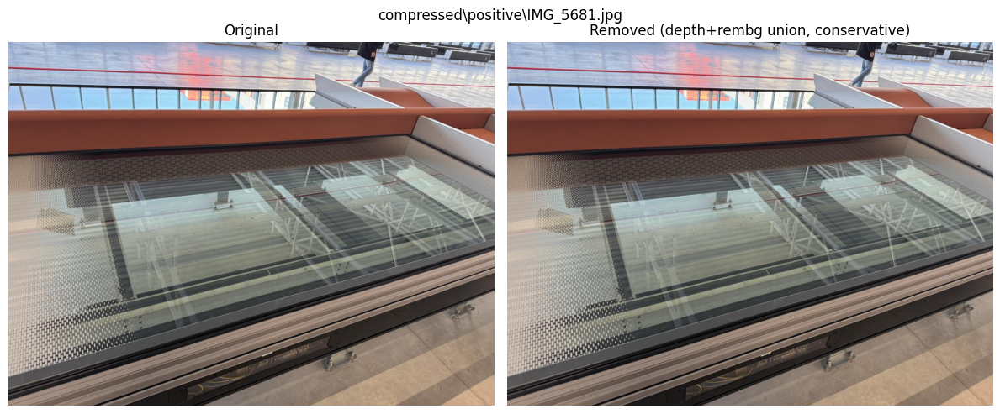

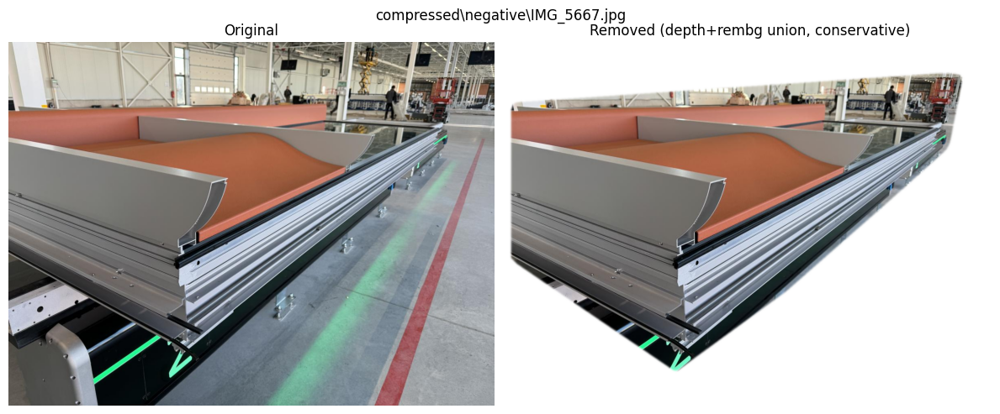

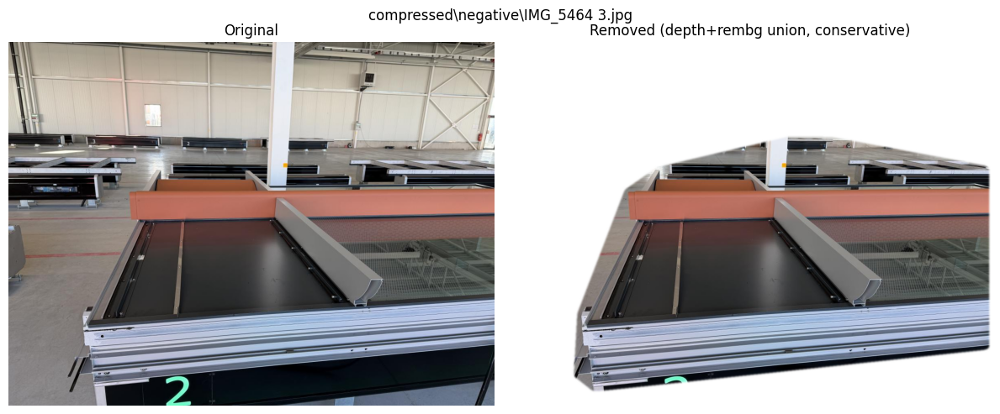

[KEEP WHOLE] | fg=0.55 bbox=0.99 touches=3 comps=82 sol=0.58 (closeup=True, unreliable=True)


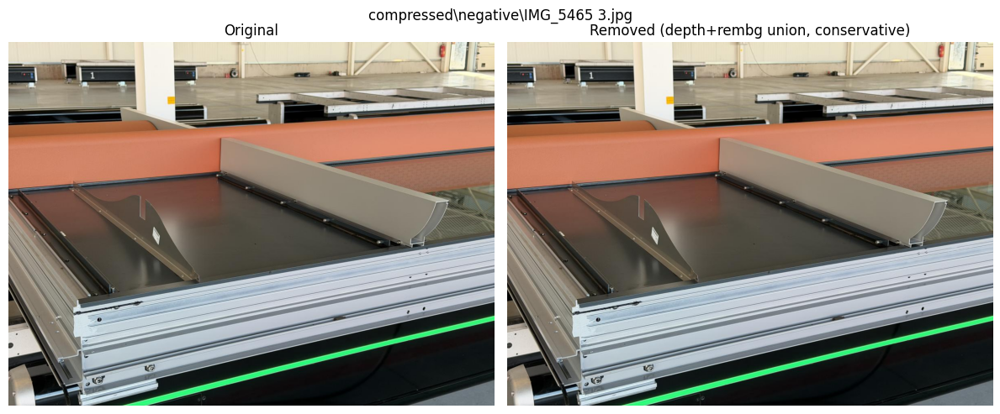

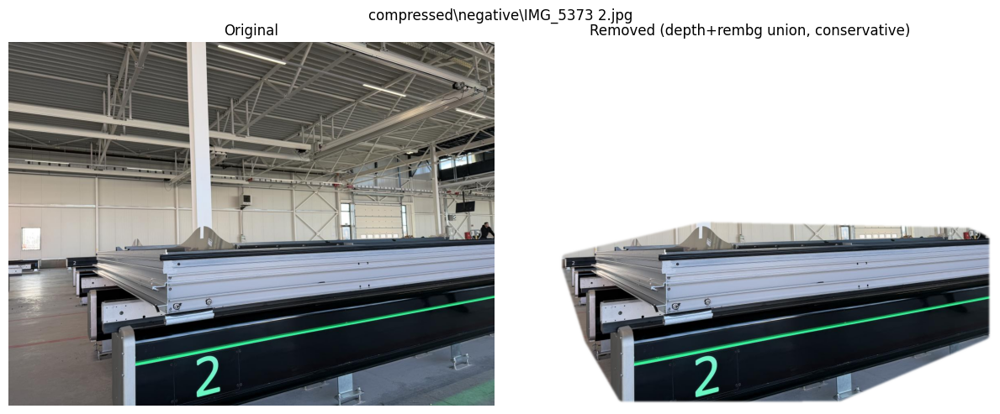

[KEEP WHOLE] | fg=0.12 bbox=0.20 touches=0 comps=6 sol=0.81 (closeup=False, unreliable=False)


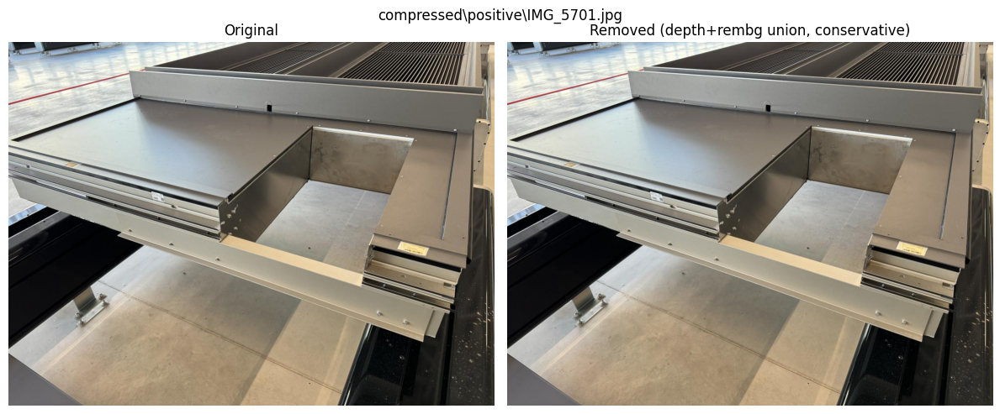

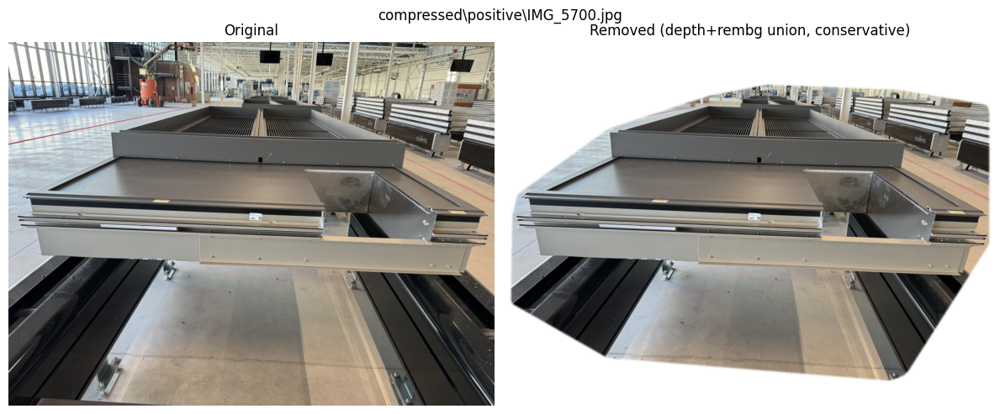

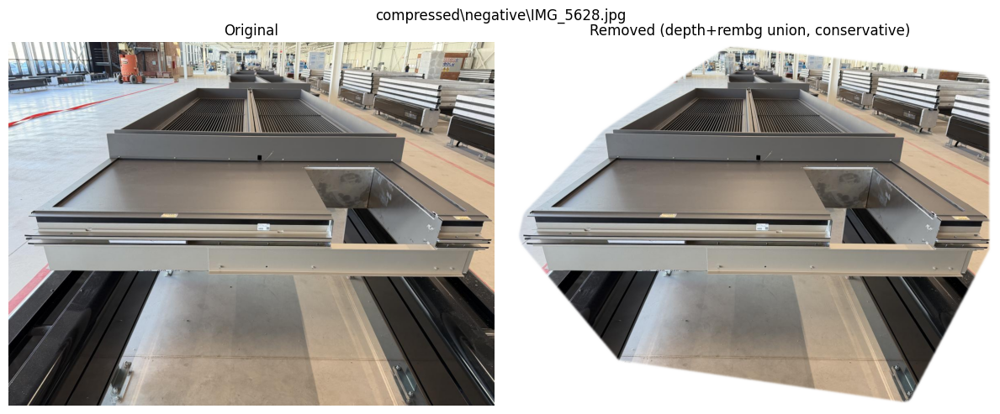

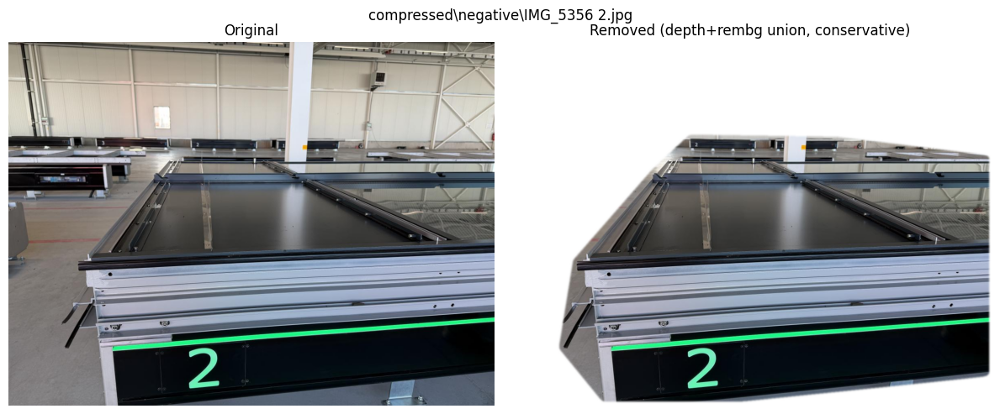

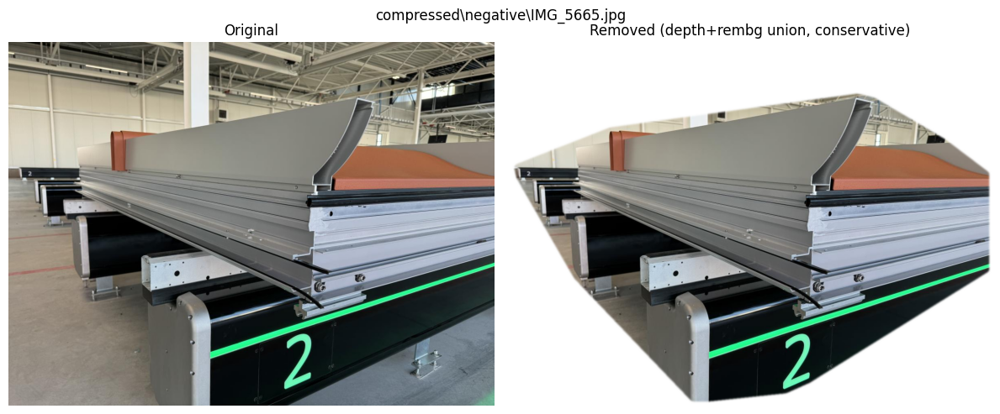

[KEEP WHOLE] | fg=0.09 bbox=0.16 touches=1 comps=2 sol=0.88 (closeup=False, unreliable=False)


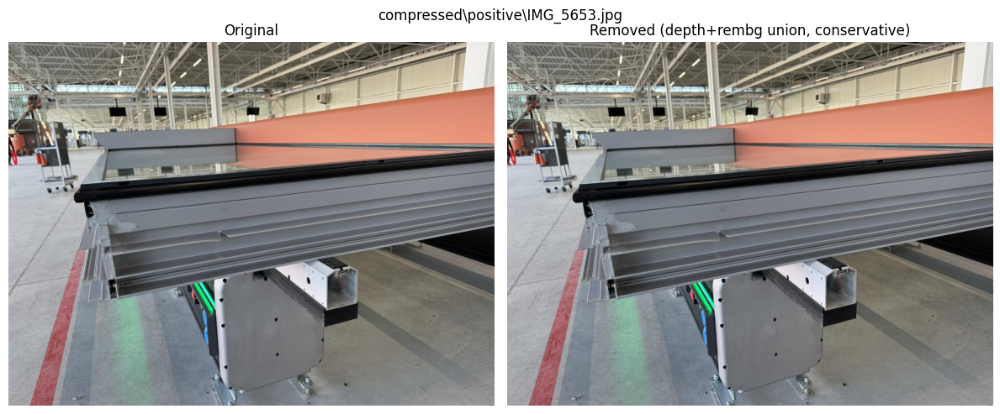

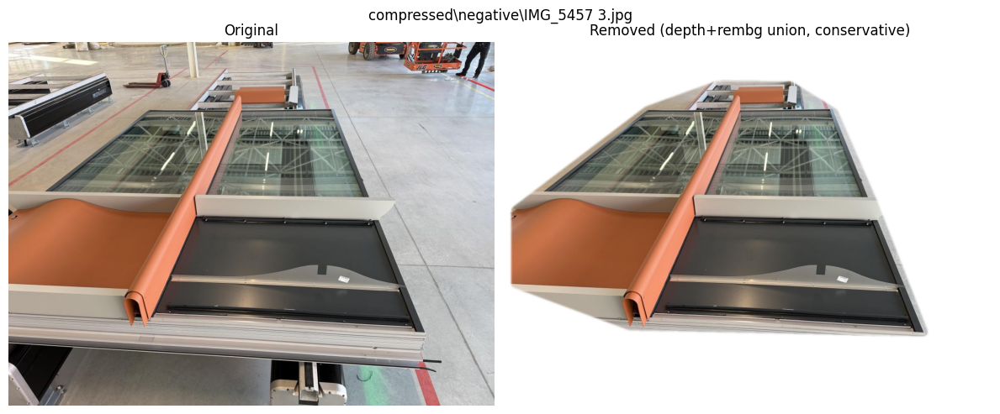

[KEEP WHOLE] | fg=0.08 bbox=0.46 touches=1 comps=4 sol=0.36 (closeup=False, unreliable=False)


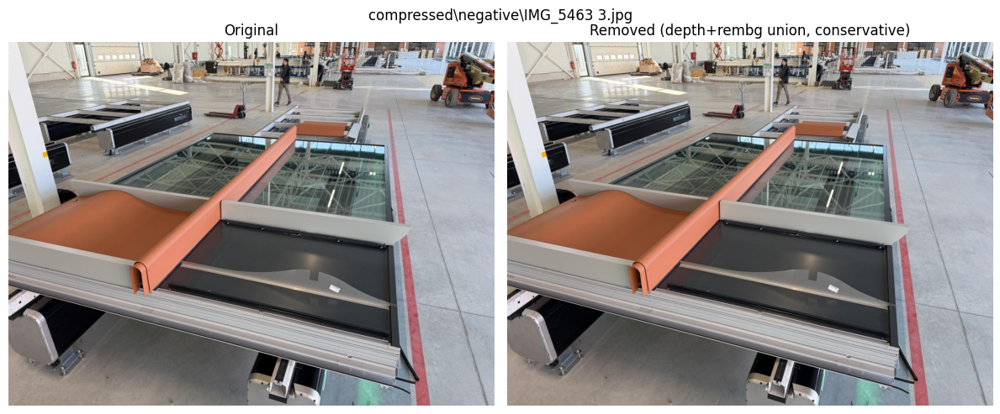

[KEEP WHOLE] | fg=0.12 bbox=0.42 touches=1 comps=3 sol=0.50 (closeup=False, unreliable=False)


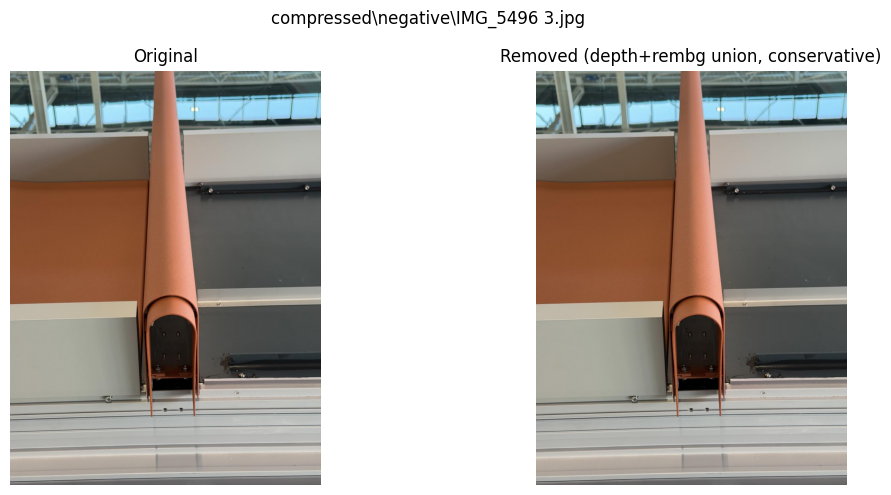

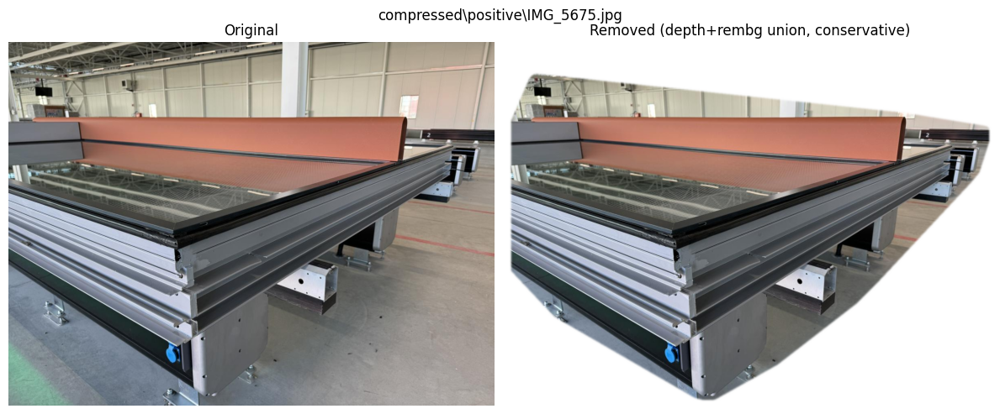

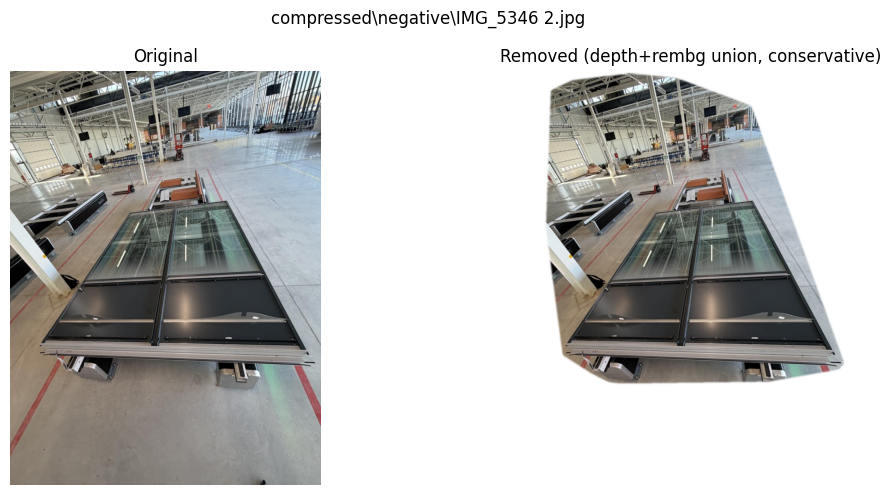

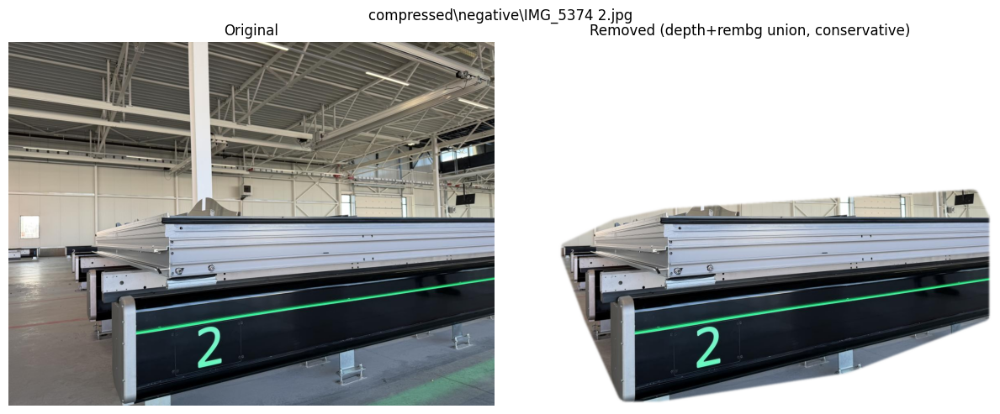

[KEEP WHOLE] | fg=0.05 bbox=0.07 touches=0 comps=2 sol=0.88 (closeup=False, unreliable=False)


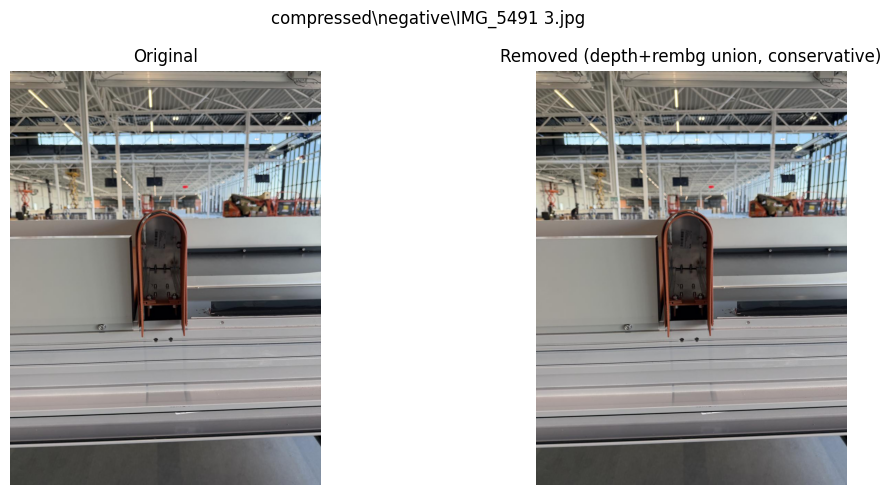

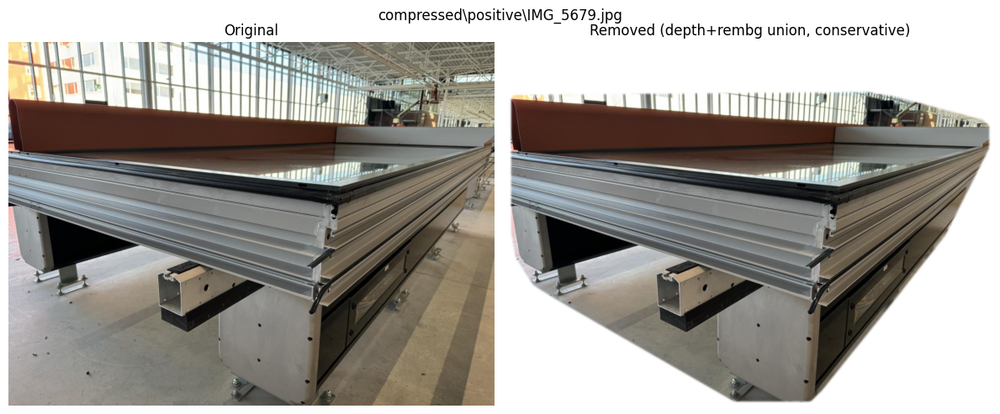

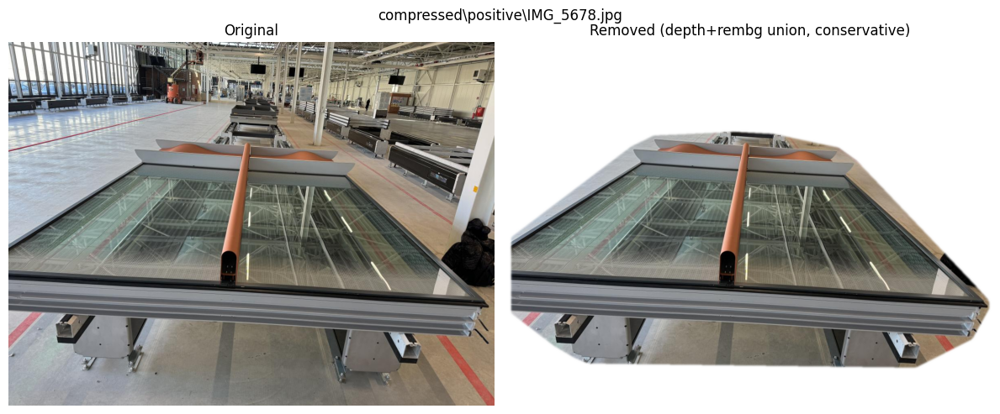

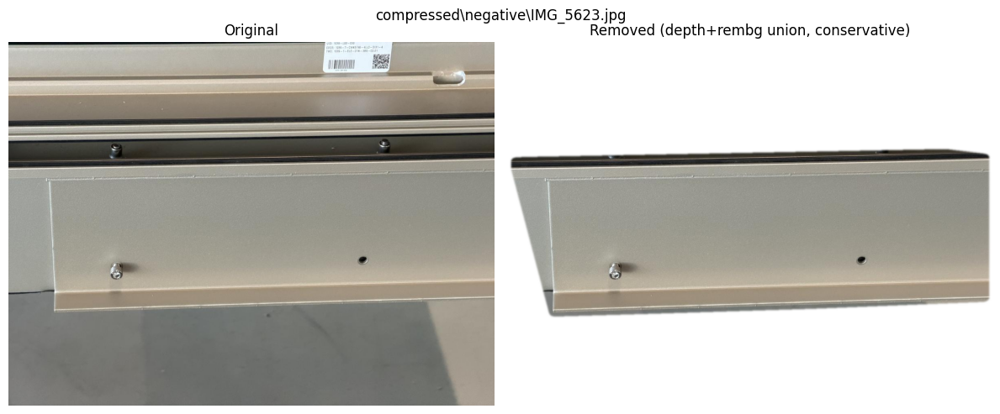

[KEEP WHOLE] | fg=0.15 bbox=0.47 touches=1 comps=3 sol=0.51 (closeup=False, unreliable=False)


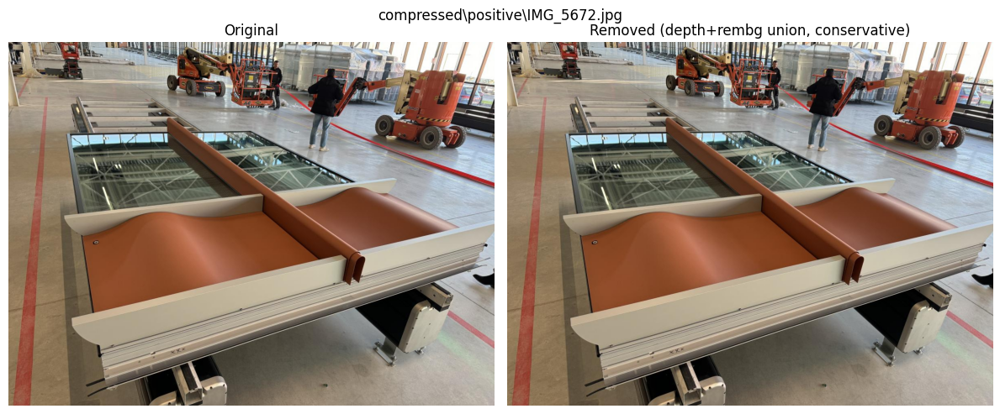

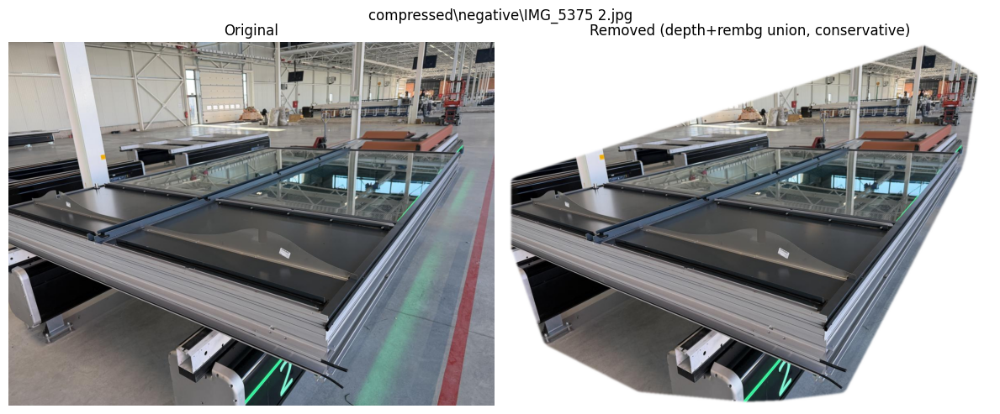

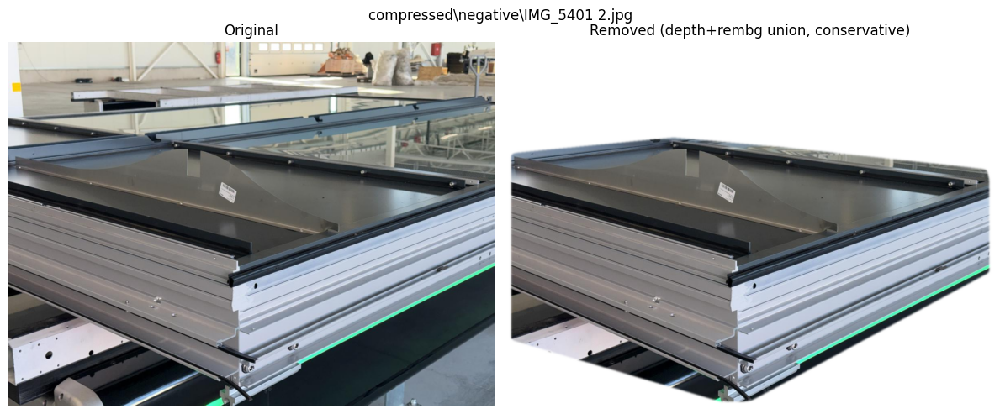

[KEEP WHOLE] | fg=0.41 bbox=1.00 touches=2 comps=16 sol=0.56 (closeup=True, unreliable=False)


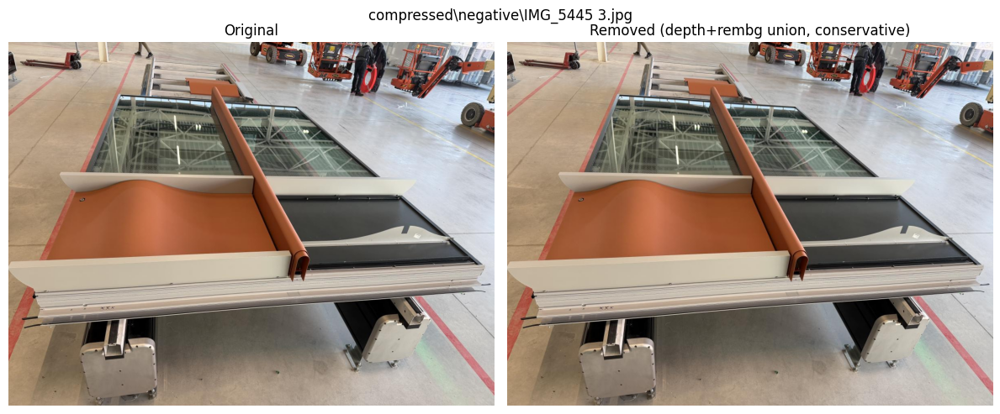

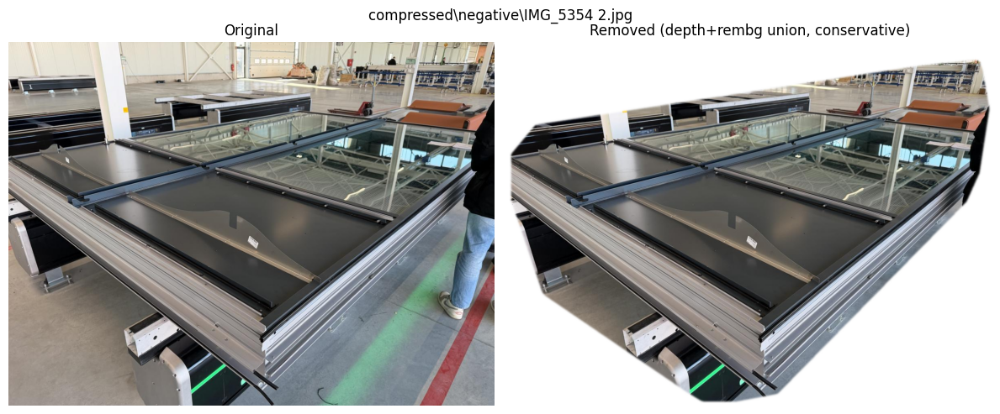

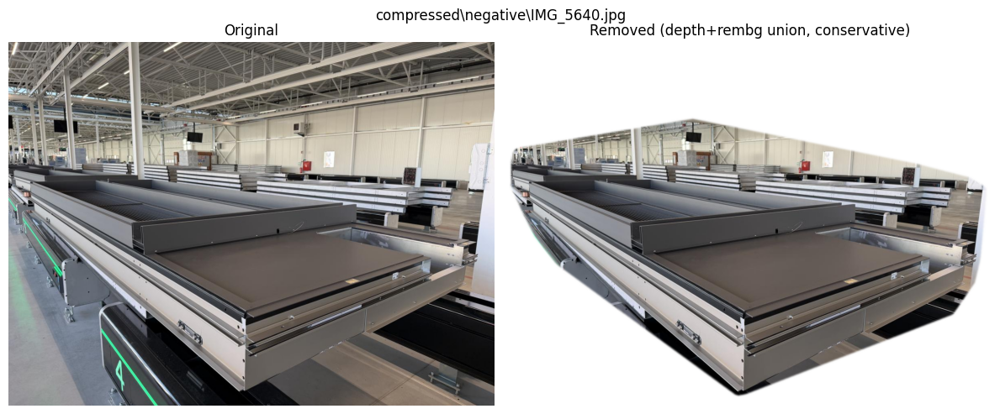

[KEEP WHOLE] | fg=0.15 bbox=0.47 touches=1 comps=38 sol=0.40 (closeup=False, unreliable=False)


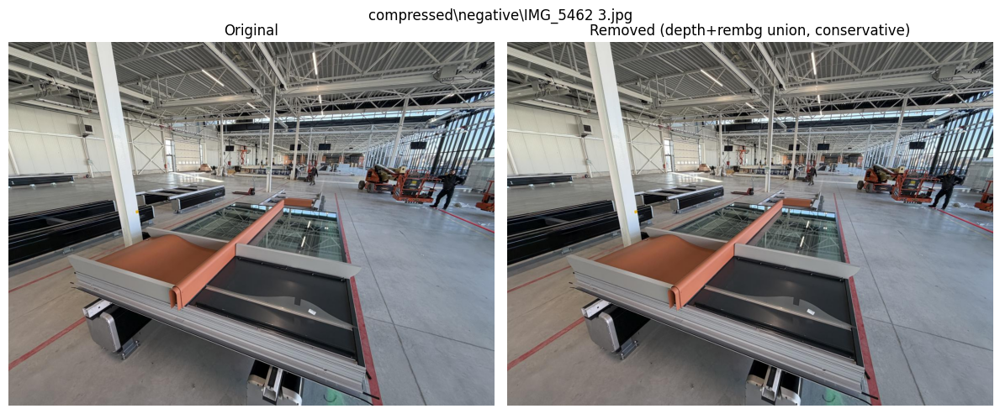

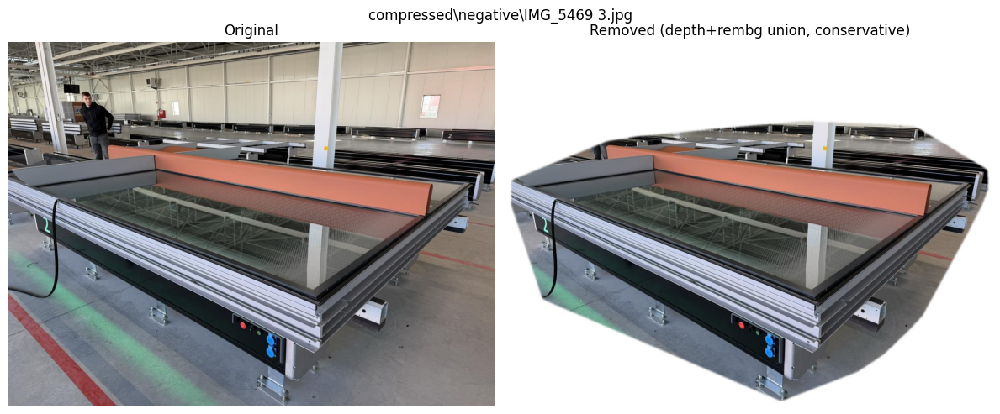

[KEEP WHOLE] | fg=0.55 bbox=0.84 touches=3 comps=57 sol=0.73 (closeup=False, unreliable=True)


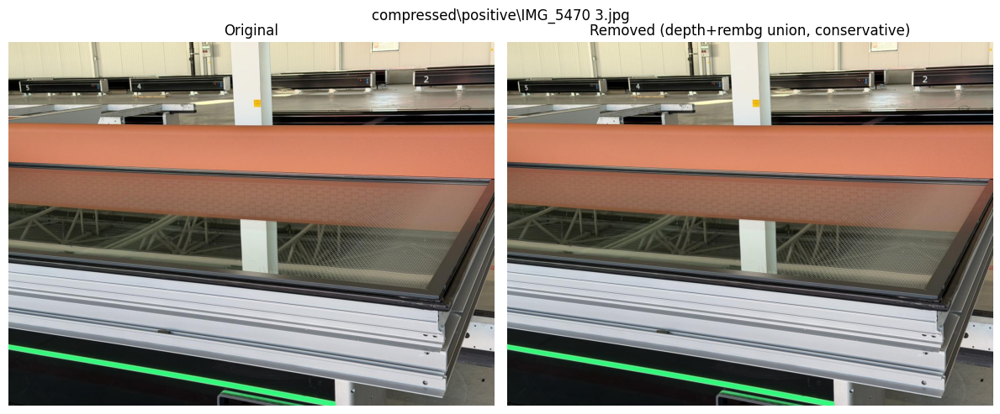

[KEEP WHOLE] | fg=0.19 bbox=0.37 touches=2 comps=6 sol=0.63 (closeup=False, unreliable=False)


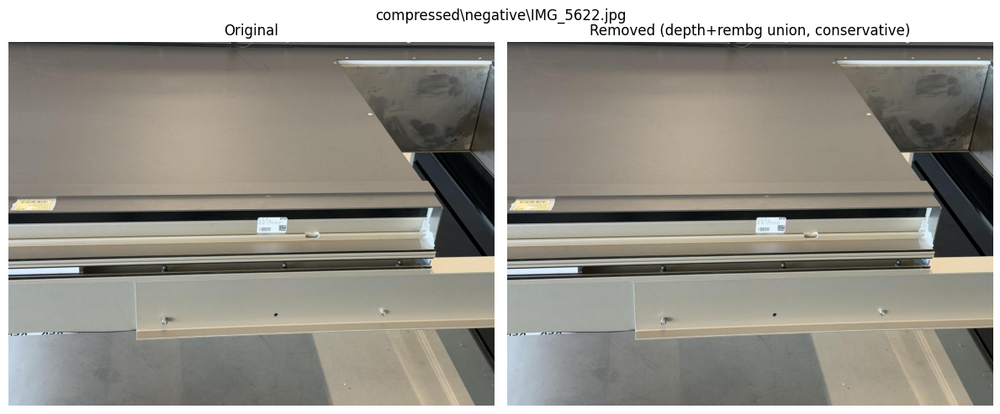

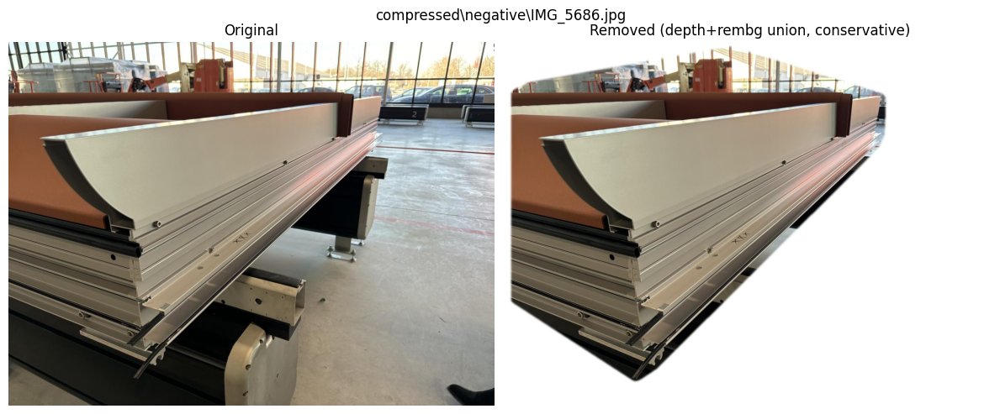

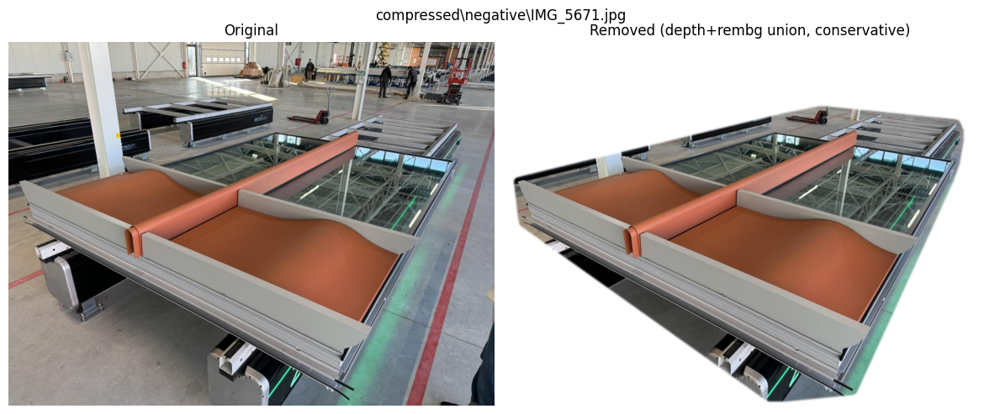

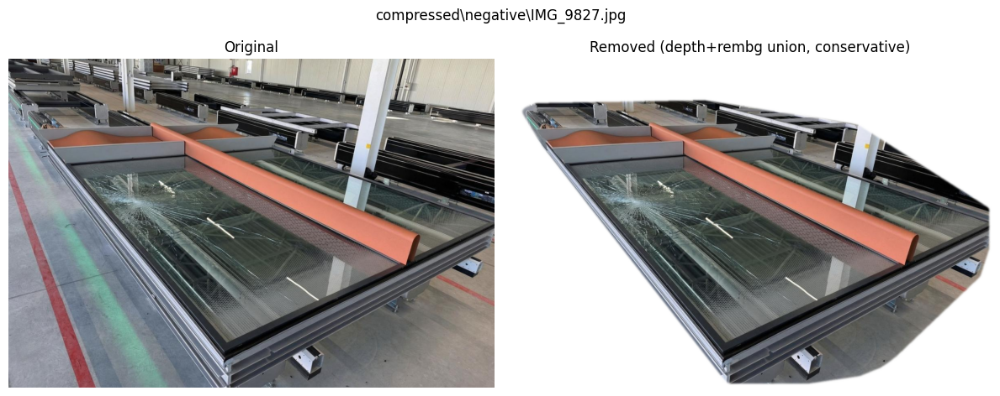

[KEEP WHOLE] | fg=0.81 bbox=1.00 touches=4 comps=15 sol=0.88 (closeup=True, unreliable=False)


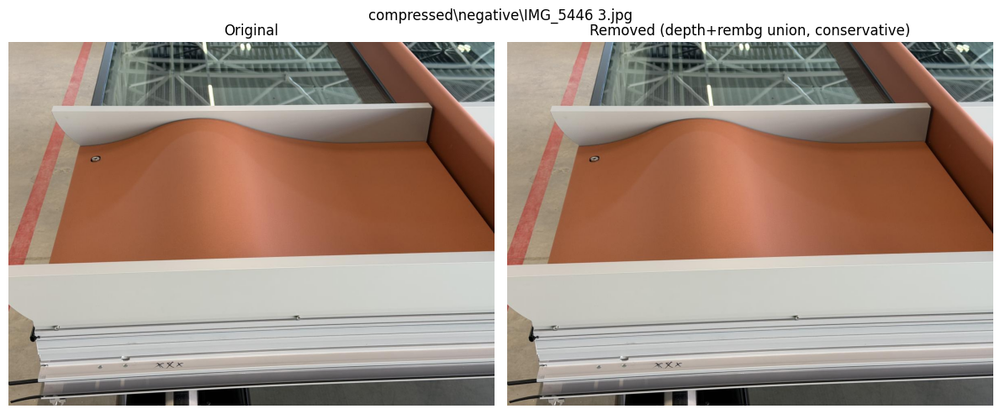

[KEEP WHOLE] | fg=0.03 bbox=1.00 touches=2 comps=66 sol=0.03 (closeup=True, unreliable=True)


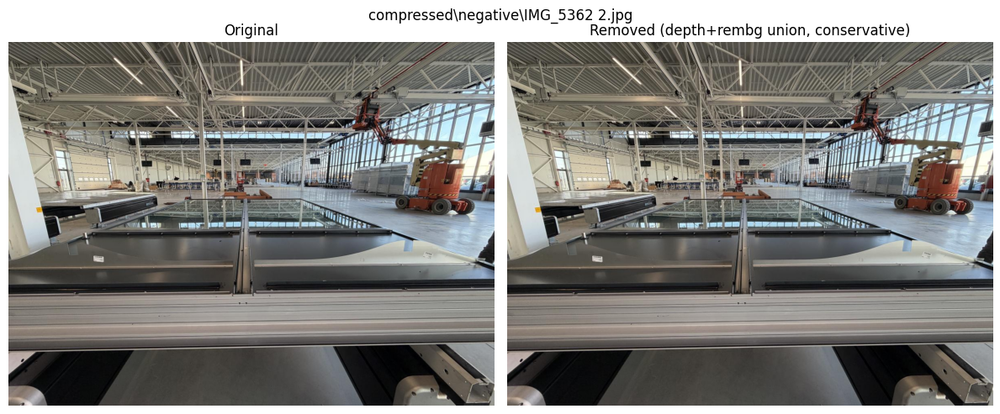

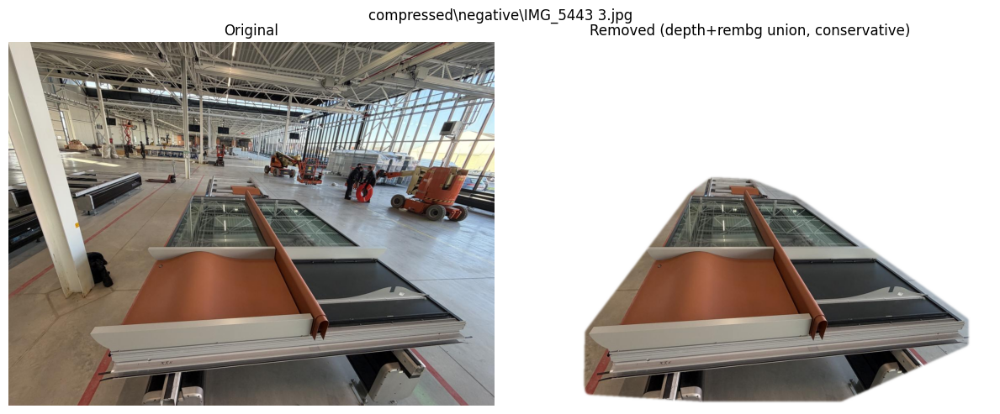

[KEEP WHOLE] | fg=0.14 bbox=0.79 touches=1 comps=76 sol=0.21 (closeup=False, unreliable=True)


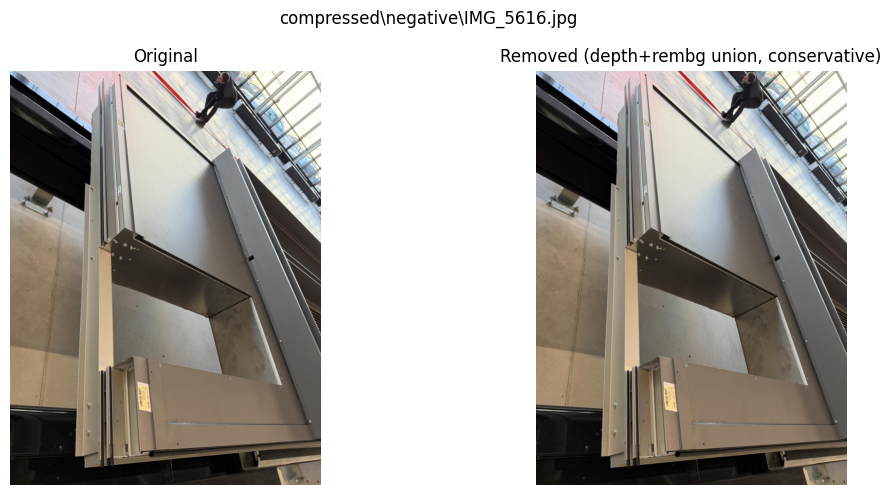

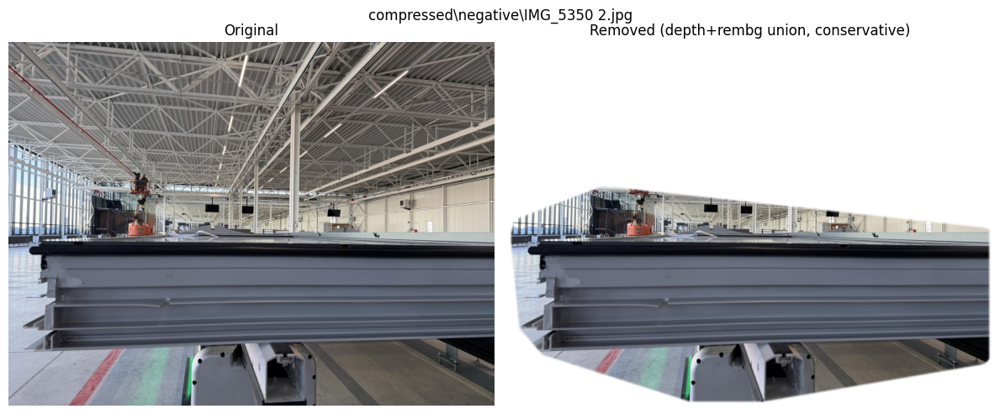

[KEEP WHOLE] | fg=0.11 bbox=0.39 touches=2 comps=30 sol=0.33 (closeup=False, unreliable=False)


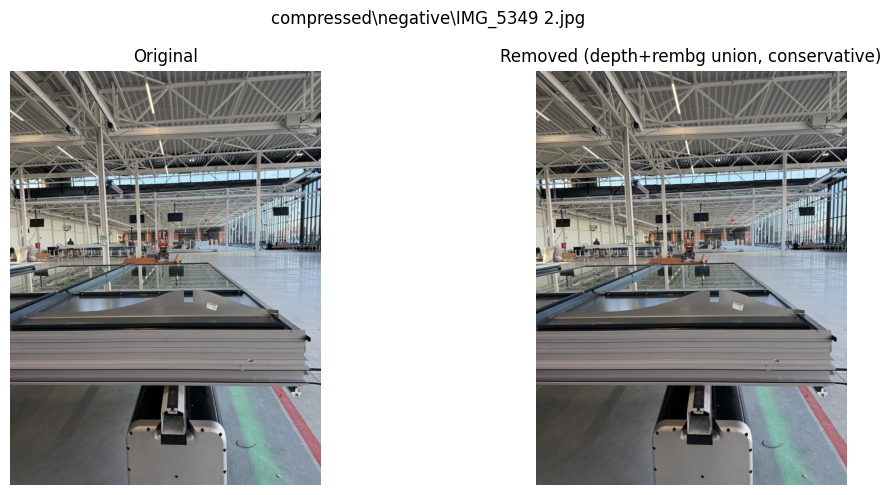

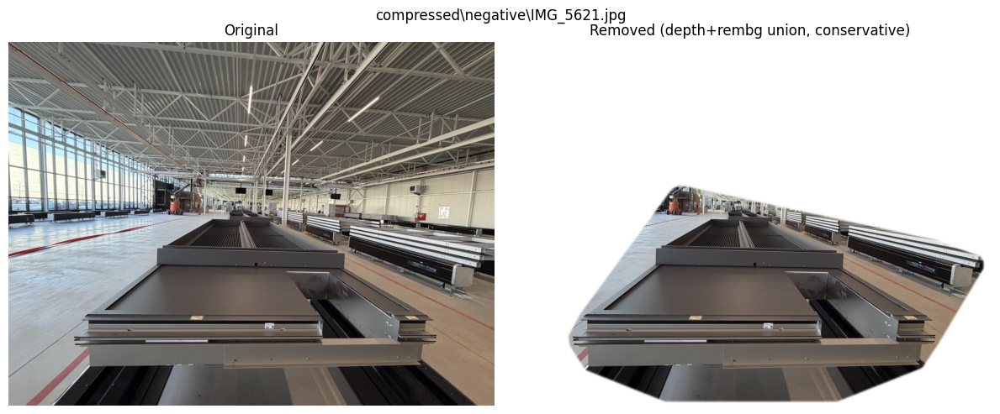

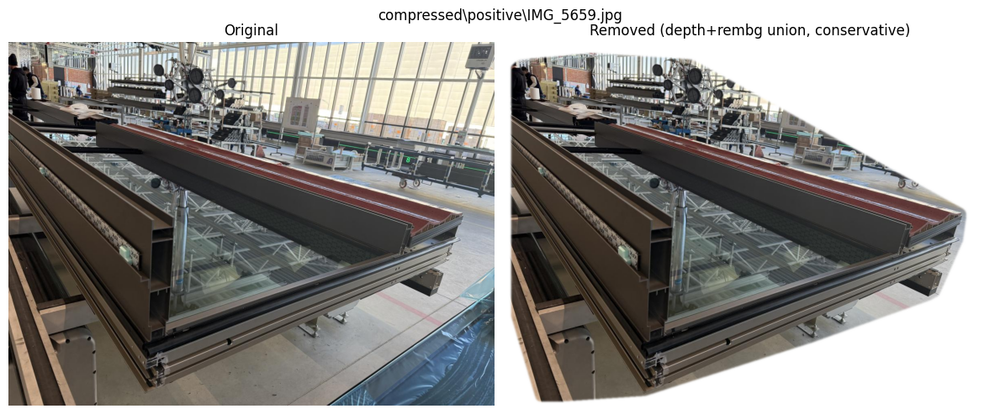

[KEEP WHOLE] | fg=0.70 bbox=0.99 touches=3 comps=6 sol=0.96 (closeup=True, unreliable=False)


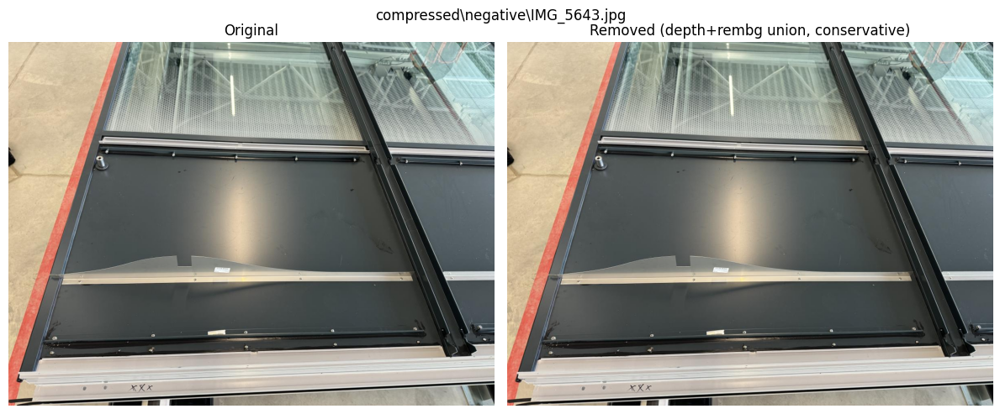

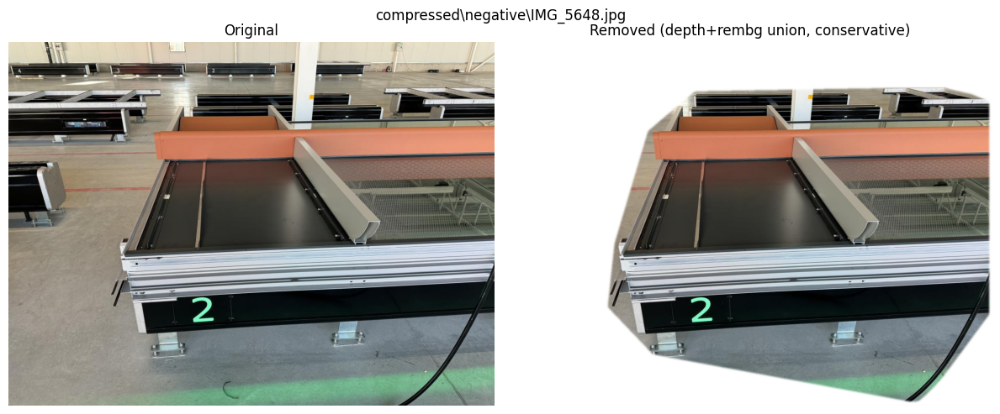

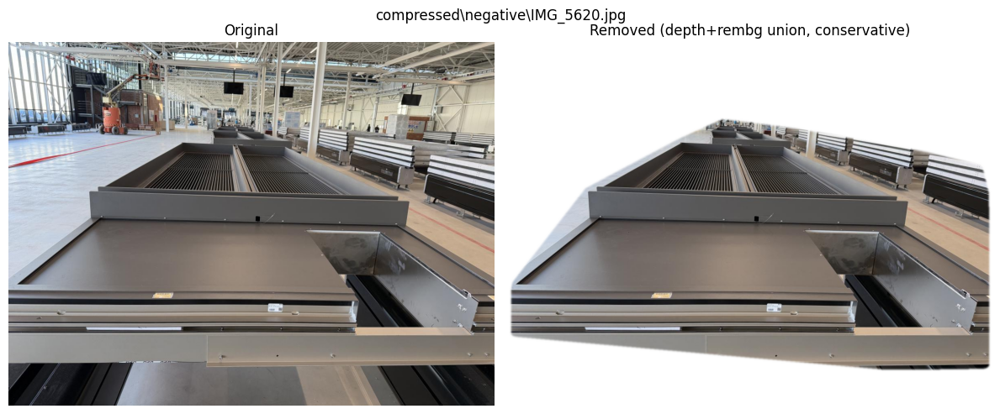

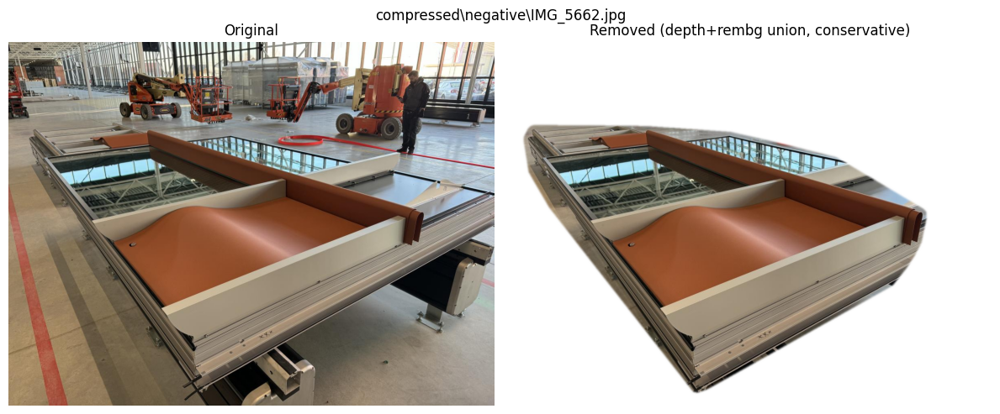

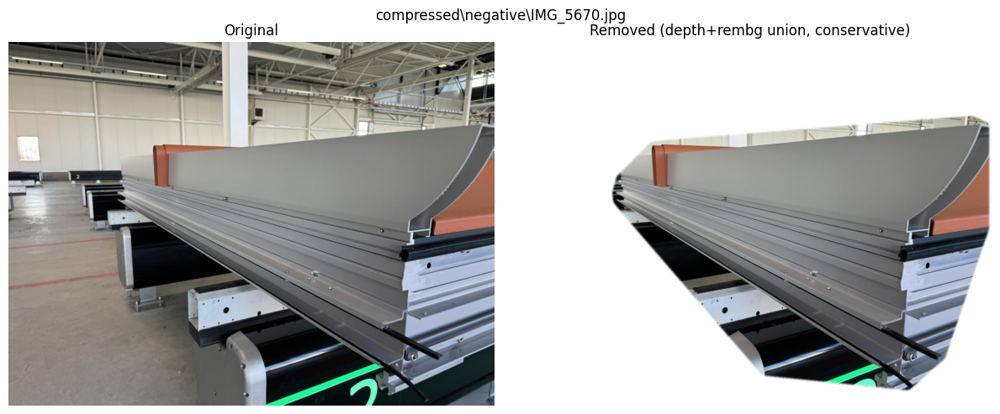

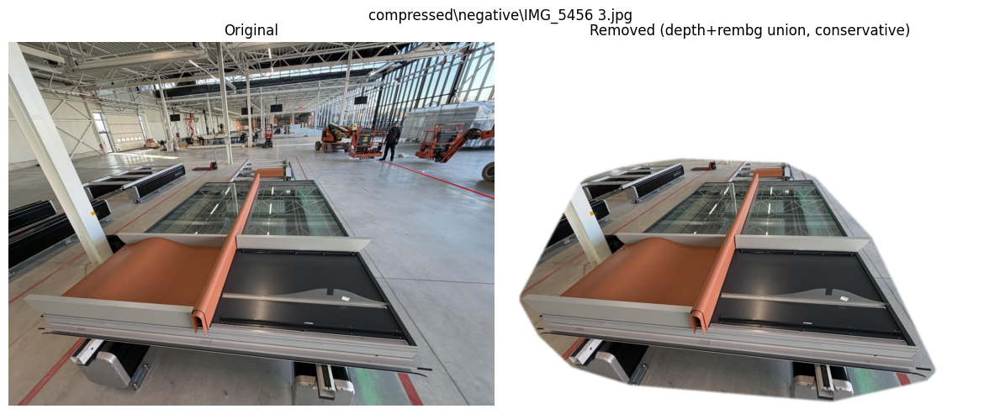

[KEEP WHOLE] | fg=0.72 bbox=1.00 touches=3 comps=6 sol=0.88 (closeup=True, unreliable=False)


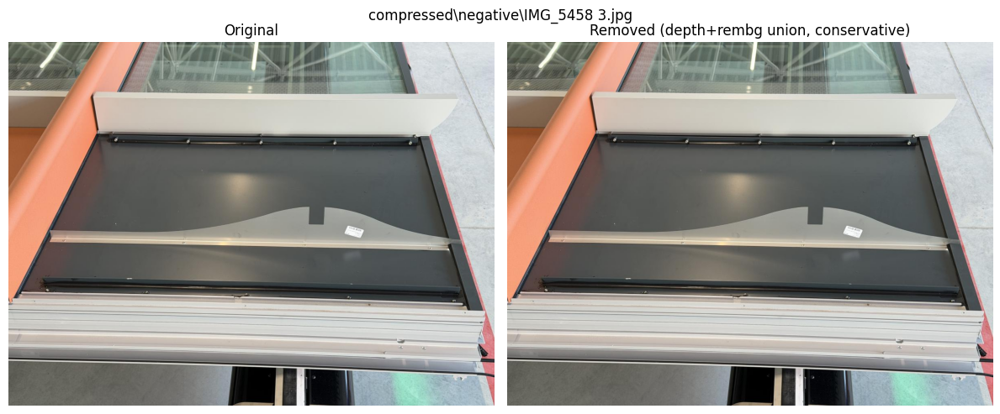

[KEEP WHOLE] | fg=0.07 bbox=0.12 touches=0 comps=4 sol=0.79 (closeup=False, unreliable=False)


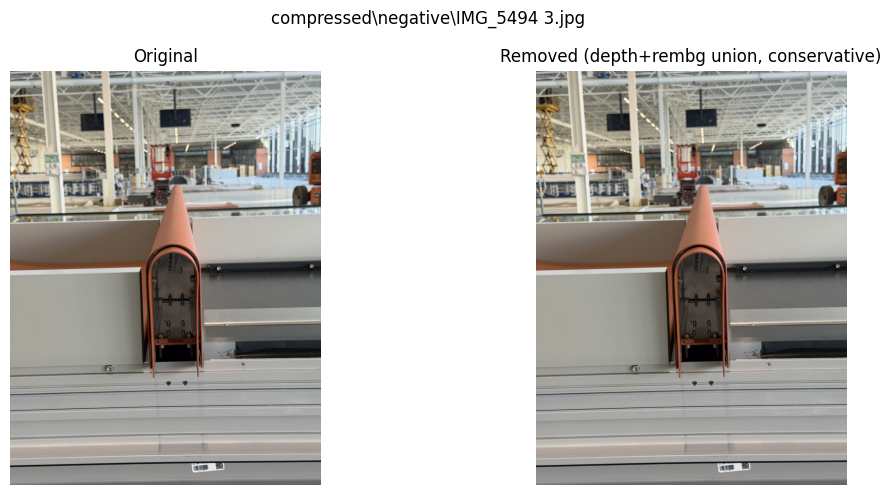

In [112]:
for p in sample_paths:
    img = Image.open(p).convert("RGB")
    rgba = conservative_foreground_rgba4(img)

    out_path = mirror_output_path(p)
    ensure_parent(out_path)
    rgba.save(out_path, format="PNG")

    show_before_after(img, rgba, title=str(p))

In [ ]:
#photos saved with only transparent pixels which are in background
for p in tqdm(all_files):
    img = Image.open(p).convert("RGB")
    rgba = conservative_foreground_rgba4(img)

    out_path = mirror_output_path(p)
    ensure_parent(out_path)
    rgba.save(out_path, format="PNG")

print("Done! All images processed.")

  2%|▏         | 1/55 [00:00<00:23,  2.25it/s]

[KEEP WHOLE] | fg=0.55 bbox=0.84 touches=3 comps=57 sol=0.73 (closeup=False, unreliable=True)


  4%|▎         | 2/55 [00:00<00:21,  2.42it/s]

[KEEP WHOLE] | fg=0.09 bbox=0.10 touches=1 comps=1 sol=0.98 (closeup=False, unreliable=False)


  5%|▌         | 3/55 [00:01<00:21,  2.47it/s]

...

 71%|███████   | 39/55 [03:27<00:21,  1.34s/it]

[KEEP WHOLE] | fg=0.14 bbox=0.79 touches=1 comps=76 sol=0.21 (closeup=False, unreliable=True)


 76%|███████▋  | 42/55 [03:44<00:44,  3.41s/it]

[KEEP WHOLE] | fg=0.19 bbox=0.37 touches=2 comps=6 sol=0.63 (closeup=False, unreliable=False)


 82%|████████▏ | 45/55 [04:08<01:04,  6.46s/it]

In [ ]:
#photos saved with white replacing background
for p in tqdm(all_files):
    img = Image.open(p).convert("RGB")
    rgba = conservative_foreground_rgba4(img)

    # REMOVE background by compositing onto white
    white_bg = Image.new("RGBA", rgba.size, (255, 255, 255, 255))
    final = Image.alpha_composite(white_bg, rgba).convert("RGB")

    out_path = mirror_output_path(p)
    ensure_parent(out_path)
    final.save(out_path, format="PNG")

print("Done! All images processed.")


  2%|▏         | 1/55 [00:00<00:25,  2.10it/s]

[KEEP WHOLE] | fg=0.55 bbox=0.84 touches=3 comps=57 sol=0.73 (closeup=False, unreliable=True)


 33%|███▎      | 18/55 [02:17<03:41,  5.99s/it]

[KEEP WHOLE] | fg=0.03 bbox=1.00 touches=2 comps=66 sol=0.03 (closeup=False, unreliable=True)


 60%|██████    | 33/55 [03:53<01:44,  4.77s/it]

[KEEP WHOLE] | fg=0.55 bbox=0.99 touches=3 comps=82 sol=0.58 (closeup=False, unreliable=True)


 71%|███████   | 39/55 [04:15<00:47,  2.94s/it]

[KEEP WHOLE] | fg=0.14 bbox=0.79 touches=1 comps=76 sol=0.21 (closeup=False, unreliable=True)


100%|██████████| 55/55 [06:04<00:00,  6.63s/it]

Done! All images processed.
